In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


float_list = ["Durée moyenne du trajet", "Retard moyen des trains en retard au départ", "Retard moyen des trains en retard à l'arrivée","Retard moyen trains en retard > 15 (si liaison concurrencée par vol)","Retard moyen de tous les trains à l'arrivée",
"Retard moyen de tous les trains au départ","Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic","Prct retard pour cause matériel roulant",
"Prct retard pour cause gestion en gare et réutilisation de matériel","Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

int_list = ["Nombre de circulations prévues","Nombre de trains annulés","Nombre de trains en retard à l'arrivée","Nombre de trains en retard au départ","Nombre trains en retard > 30min","Nombre trains en retard > 60min","Nombre trains en retard > 15min"]

check_if_zero = ["Durée moyenne du trajet","Nombre de circulations prévues"]

ignore_zero_columns = ["Nombre de trains annulés", "Nombre de trains en retard à l'arrivée", 
                       "Nombre de trains en retard au départ", "Nombre trains en retard > 30min",
                       "Nombre trains en retard > 60min", "Nombre trains en retard > 15min",
                       "Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic",
                       "Prct retard pour cause matériel roulant","Prct retard pour cause gestion en gare et réutilisation de matériel",
                       "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

# create dataframe and clear row and duplicate row
data = pd.read_csv('project_dataset.csv', on_bad_lines='warn', sep=';')
data.drop(['Commentaire annulations','Commentaire retards au départ',"Commentaire retards à l'arrivée"],axis=1,inplace=True)
data = data.replace(
    ['', ' ', 'NC', 'Non communiqué', 'N/A', '-', 'None', 'NONE', 'nan', 'NaN'],
    np.nan
)




# Strips the strings, replaces spaces and / to -, and formats to year-month-days dates.
data['Date'] = data['Date'].str.strip().str.replace(' ',"-").str.replace('/','-')
data['Date'] = pd.to_datetime(data['Date'], format='mixed')

# Creates year and month dataframes.
YearDf = data['Date'].dt.year
monthDf = data['Date'].dt.month

## change value if case is empty
for element in data:
    if element in float_list or element in int_list:
        data[element] = data[element].astype(str).replace(['', 'NC', 'Non communiqué', 'N/A','-',' '], np.nan)
    else:
        data[element] = data[element].replace('', np.nan)
        data[element] = data[element].replace('NC', np.nan)
        data[element] = data[element].replace('Non communiqué', np.nan)
        data[element] = data[element].replace('N/A', np.nan)
        data[element] = data[element].replace('-', np.nan)

# format line to dataframe
for element in data:
    if element in float_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip().astype(float).round(2)
    elif element in int_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip()
        data[element] = pd.to_numeric(data[element], errors='coerce').fillna(0).astype(int)
    elif element == "Gare de départ" or element == "Gare d'arrivée":
        data[element] = data[element].str.upper().str.replace("SAINT","ST").str.replace("TGV","").str.replace('0', '').str.replace('1', '').str.replace('2', '').str.replace('3', '').str.replace('4', '').str.replace('5', '').str.replace('6', '').str.replace('7', '').str.replace('8', '').str.replace('9', '').str.strip()

# check if the value is 0.0 and drop the row if it is          
for index in check_if_zero:
    data = data[data[index] != 0]

# check all line if it's ok and drop the row if not
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"] + data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard à l'arrivée"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 30min"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 60min"]]

data = data[data["Prct retard pour cause gestion en gare et réutilisation de matériel"]+ data["Prct retard pour causes externes"]
            + data["Prct retard pour cause infrastructure"] + data["Prct retard pour cause gestion trafic"] + data["Prct retard pour cause matériel roulant"] 
            + data["Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"] <= 100.1]


for col in ["Gare de départ", "Gare d'arrivée"]:
    data[col] = data[col].replace({
        '': np.nan,
        'nan': np.nan,
        'NaN': np.nan,
        'None': np.nan,
        'NONE': np.nan
    })



data = data[data['Date'].notna()]

# remove row if lot of 0 in the row

for index, row in data.iterrows():
    count_zero = 0
    count_nan = 0
    suspect_zero = 0
    for col in data.columns:
        if col not in ignore_zero_columns:
            value = str(row[col])
            if value == '0' or value == '0.0':
                count_zero += 1
            if pd.isna(row[col]):
                count_nan += 1
        suspect_zero = count_nan + count_zero
    if suspect_zero > 3:
        data = data.drop(index)

data.drop_duplicates(inplace=True)

# Feature Engineering: Fiabilité de la ligne (Inversée pour que 1 = Parfait)
data['fiabilite de la ligne'] = 1 - (
    (data['Nombre de trains annulés'] + data["Nombre de trains en retard à l'arrivée"]) / 
    data['Nombre de circulations prévues']
)

data["fiabilite de la ligne"] = data['fiabilite de la ligne'].astype(float).round(2)

data["fiabilite de la ligne"] = data["fiabilite de la ligne"].clip(lower=0)

# remove all data if is equals none
for element in data:
    data = data.dropna(subset=[element])
# Create new csv file with cleaned data
data.to_csv('cleaned_dataset.csv', index=False)

In [16]:
##  add cleaned data to a new dataframe and display info
cleaned_data = pd.read_csv('cleaned_dataset.csv')
cleaned_data['Date'] = pd.to_datetime(cleaned_data['Date'], format='ISO8601')
cleaned_data.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8834 entries, 0 to 8833
Data columns (total 23 columns):
 #   Column                                                                                       Non-Null Count  Dtype         
---  ------                                                                                       --------------  -----         
 0   Date                                                                                         8834 non-null   datetime64[ns]
 1   Gare de départ                                                                               8834 non-null   object        
 2   Gare d'arrivée                                                                               8834 non-null   object        
 3   Durée moyenne du trajet                                                                      8834 non-null   float64       
 4   Nombre de circulations prévues                                                               8834 non-null   int64

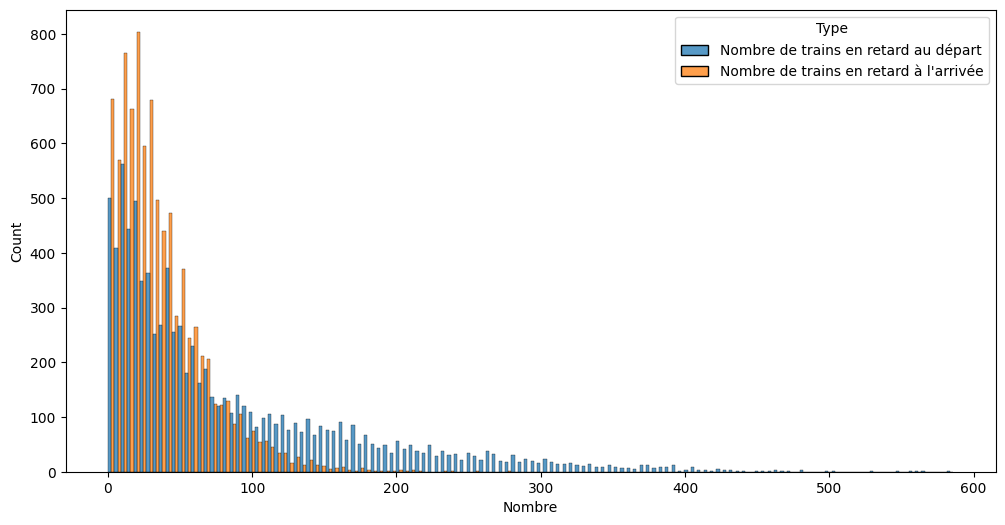

In [17]:
plt.figure(figsize=(12,6))
plot_data = cleaned_data.melt(
    value_vars=[
        "Nombre de trains en retard au départ",
        "Nombre de trains en retard à l'arrivée"
    ],
    var_name="Type",
    value_name="Nombre"
)

# Single histplot with hue
sns.histplot(
    data=plot_data,
    x="Nombre",
    hue="Type",
    multiple="dodge"
)
plt.show()

<Axes: >

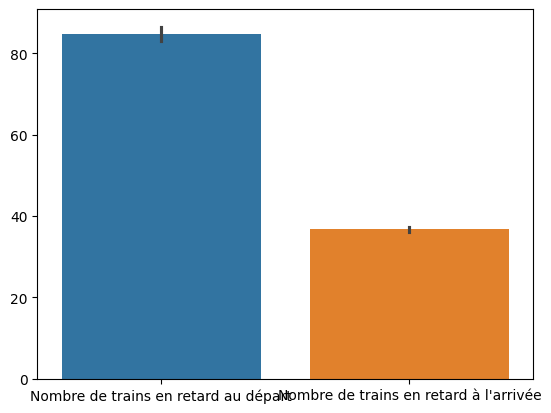

In [18]:
sns.barplot(data = cleaned_data[["Nombre de trains en retard au départ","Nombre de trains en retard à l'arrivée"]] )


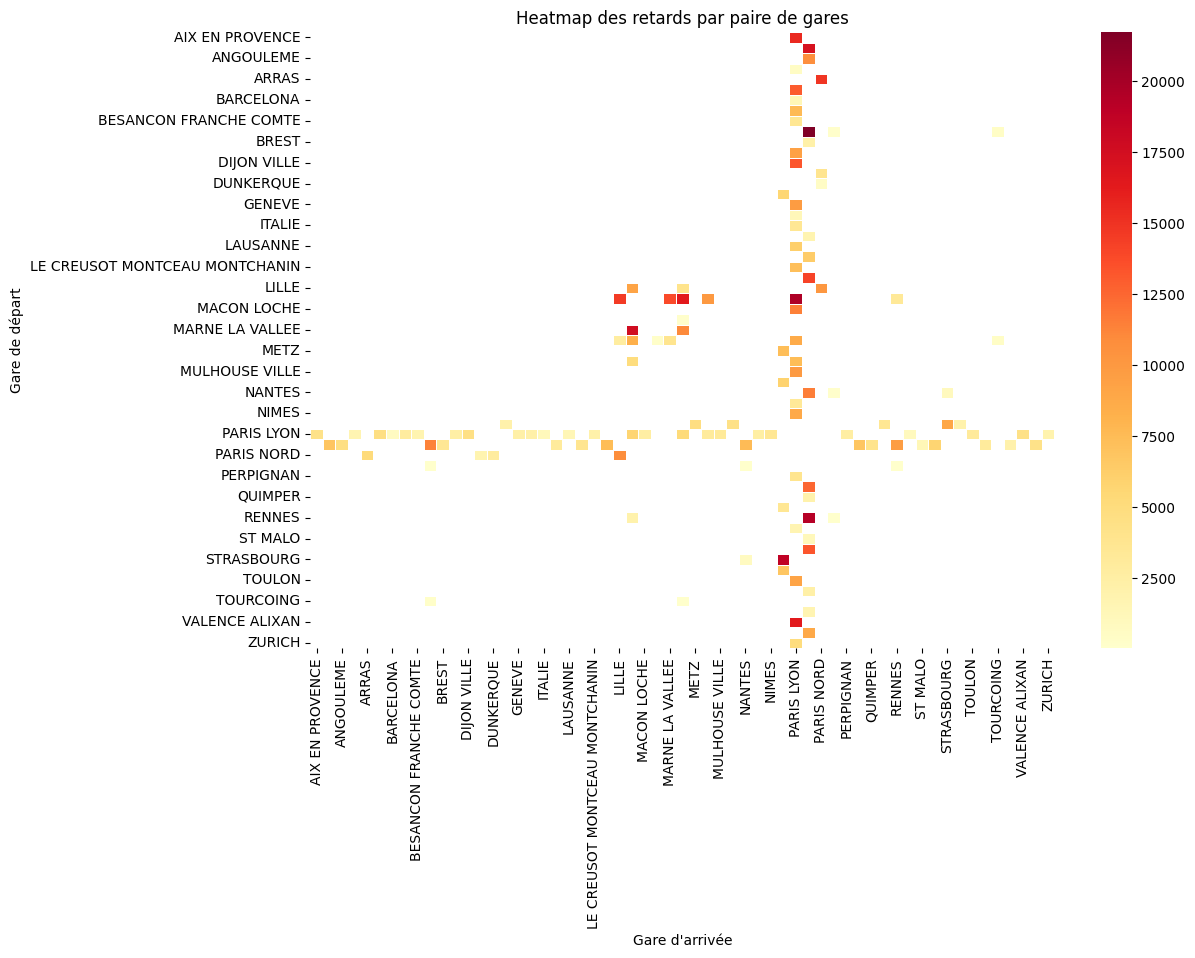

In [19]:
plt.figure(figsize=(12,8))

pivot = cleaned_data.pivot_table(
    index="Gare de départ",
    columns="Gare d'arrivée",
    values="Nombre de trains en retard au départ",
    aggfunc="sum"
)

sns.heatmap(
    pivot,
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Heatmap des retards par paire de gares")
plt.show()

In [20]:
total_departure_delays = cleaned_data["Nombre de trains en retard au départ"].sum()
total_arrival_delays = cleaned_data["Nombre de trains en retard à l'arrivée"].sum()
total_trains = cleaned_data["Nombre de circulations prévues"].sum()
total_trains_canceled = cleaned_data["Nombre de trains annulés"].sum()
total_trains_ok = total_trains - total_trains_canceled - total_departure_delays - total_arrival_delays
total_trains_not_ok = total_trains - total_trains_ok
print("Il y a",total_trains_ok,"trains corrects pour",total_trains_not_ok,"trains pas corrects.")
print(round((total_trains_ok / total_trains)*100),"%","des trains performent correctement.")
print(round(((total_arrival_delays + total_departure_delays)/ total_trains)*100),"%","des trains sont en retards.")


mean_delays_departure = cleaned_data['Retard moyen des trains en retard au départ'].mean()
mean_delays_arrival = cleaned_data["Retard moyen des trains en retard à l'arrivée"].mean()
mean_delays_total_departure = cleaned_data['Retard moyen de tous les trains au départ'].mean()
mean_delays_total_arrival = cleaned_data["Retard moyen de tous les trains à l'arrivée"].mean()
print("Moyenne du temps de retard  :",(mean_delays_departure + mean_delays_arrival)/2, "min")
print("Moyenne du temps de retard comprenant les trains arrivés à l'heure:",(mean_delays_total_departure+mean_delays_total_arrival)/2, "min")




Il y a 1251530 trains corrects pour 1147887 trains pas corrects.
52 % des trains performent correctement.
45 % des trains sont en retards.
Moyenne du temps de retard  : 23.884184401177272 min
Moyenne du temps de retard comprenant les trains arrivés à l'heure: 4.807737717908083 min


In [21]:
df = pd.read_csv("cleaned_dataset.csv")



plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Retard moyen de tous les trains à l'arrivée", bins=50)
plt.title("Distribution des retards moyens à l'arrivée")    
plt.savefig("png/distribution_retards.png")
plt.close()

top_stations = df.groupby("Gare de départ")["Retard moyen de tous les trains à l'arrivée"].mean().reset_index()
top_stations = top_stations.sort_values(by="Retard moyen de tous les trains à l'arrivée", ascending=False).head(10)
                                      
plt.figure(figsize=(12, 6))
sns.barplot(data=top_stations, x="Retard moyen de tous les trains à l'arrivée", y="Gare de départ")
plt.title("Top 10 des gares avec le plus fort retard moyen au départ")
plt.savefig("png/top_gares.png")
plt.close()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Month"] = df["Date"].dt.month

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Month", y="Retard moyen de tous les trains à l'arrivée", estimator="mean", errorbar=None, marker="o")
plt.title("Évolution du retard moyen par mois")
plt.grid(True, linestyle="--", alpha=0.7)
plt.savefig("png/evolution_retard_mois.png")
plt.close()

causes = [
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
]
mean_causes = df[causes].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=mean_causes.values, y=mean_causes.index)
plt.title("Répartition moyenne des causes de retard")
plt.xlabel("Pourcentage moyen")
plt.tight_layout()
plt.savefig("png/causes_retard.png")
plt.close()

df_nantes = df[df["Gare de départ"].str.contains("NANTES", na=False)]
top_nantes_dest = df_nantes.groupby("Gare d'arrivée")["Retard moyen de tous les trains à l'arrivée"].mean().sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_nantes_dest.values, y=top_nantes_dest.index)
plt.title("Top 5 des pires destinations au départ de Nantes")
plt.xlabel("Retard moyen à l'arrivée (minutes)")
plt.tight_layout()
plt.savefig("png/nantes_retards.png")
plt.close()


plt.figure(figsize=(10, 6))
sns.regplot(
    data=df, 
    x="Durée moyenne du trajet", 
    y="Retard moyen des trains en retard à l'arrivée", 
    scatter_kws={"alpha": 0.3}, 
    line_kws={"color": "red"}
)
plt.title("Corrélation entre la durée du trajet et le retard moyen à l'arrivée")
plt.savefig("png/correlation_duree_retard.png")
plt.close()


plt.figure(figsize=(10, 6))
sns.regplot(
    data=df, 
    x="Durée moyenne du trajet", 
    y="Retard moyen des trains en retard au départ", 
    scatter_kws={"alpha": 0.3}, 
    line_kws={"color": "red"}
)
plt.title("Corrélation entre la durée du trajet et le retard moyen au départ")
plt.savefig("png/correlation_duree_retard_depart.png")
plt.close()

